# Figures for the bicoherence-pattern paper

Run the cells in order. The notebook writes four PDFs to `figures/`:

| Figure | File |
| --- | --- |
| Web, cross and hypotenuse patterns | `patterns_9panel.pdf` |
| The same, plus the point state | `patterns_12panel.pdf` |
| Pattern in the (η, 𝒬) plane | `eta_Q_grid.pdf` |
| The (η, 𝒬) plane on a web-matched base | `eta_Q_grid_web.pdf` |

The cells you're most likely to want to edit are **Model parameters** and
**Plotting options**. The plotting helpers in between can be left alone.

## Setup

In [1]:
import os, json
import importlib
from pprint import pprint

import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

import sim_lightcurve as sm
import sim_dQ_grid as dq
sm = importlib.reload(sm)  # pick up edits to the modules without restarting the kernel
dq = importlib.reload(dq)

plt.rcParams['figure.dpi'] = 300  # resolution of the inline previews only; the PDFs are vector

# Segments averaged per bicoherence estimate. The b2 noise floor is 1/K, so K = 1000 gives
# a floor of 1e-3. Each segment is sm.NSEG = 2048 bins of sm.DT = 1/64 s (32 s).
sm.K = 1000
sm.NTOT = sm.NSEG * sm.K

OUTROOT = 'figures'  # figure PDFs are written here, relative to this notebook
os.makedirs(OUTROOT, exist_ok=True)

## Model parameters

The light curve is

x(t) = e^{g − σ²/2} [1 + a₁ cos φ + a₂ cos(2φ + θ)] + (locked term κ₂ (G ∗ q₂)(t) at ν₀) + D [1 + d(t)],

sampled with Poisson counts. Here g is the flow noise, q₂ = g² − ⟨g²⟩ its quadratic
part, and d(t) the slow dilution. Every state below is the web state with a few
parameters changed. Anything not listed keeps the default of `sm.Params`; its
docstring (`help(sm.Params)`) describes every field.

In [2]:
WEB = sm.Params(
    # QPO (tone) at nu0
    nu0=1.5,          # QPO frequency (Hz)
    a1=.2,            # rms fractional amplitude of the fundamental
    a2=.05,           # rms fractional amplitude of the 2 nu0 harmonic
    th=np.pi/2,       # phase of the harmonic (rad)

    # Flow noise g, which multiplies the QPO: a broken power law, flat below pl_fb
    g_psd='powerlaw',
    pl_fb=1.5,        # break frequency (Hz)
    pl_slope=2.,      # P ~ f^-pl_slope above the break
    sig_g=.2,         # rms of g

    # Locked (quadratic) term: kappa2 e^{i argk} (G * q2), placed at nu0
    kappa2=.1,        # rms of the locked term; 0 switches it off
    kernel='flat',    # 'flat': unit response over nu0 +/- dband (flat biphase);
                      # 'lorentzian': driven mode with quality factor Qres (biphase rotates)
    dband=.1,         # half-width (Hz) of the flat kernel's band
    argk=np.pi/2,     # phase of kappa2 (rad)

    # Slow dilution D (1 + nd_rms d(t)), where d(t) is unit-rms red noise
    D=0.3,            # mean level, relative to the flow's mean of 1
    nd_psd='powerlaw',
    nd_fb=1.5,        # break frequency (Hz) of d(t)'s power spectrum
)

# Cross: raise the low-frequency dilution (a higher level, with a lower break).
CROSS = sm.replace(WEB, D=3.5, nd_fb=.5)

# Hypotenuse: weaken the QPO and move it up in frequency.
HYP = sm.replace(WEB, a1=.01, nu0=5)

# Point (type-B-like): weak flow noise and dilution, QPO at 5 Hz; only (nu0, nu0) survives.
POINT = sm.replace(WEB, sig_g=.015, D=.005, nu0=5)

# Base of the second (eta, Q) plane: WEB with nu0 = 5, a steeper flow slope and the
# dilution cut off at and above nu0. The grid varies a1 and nd_rms around this base.
# (The first plane's base is dq.BASE, defined in sim_dQ_grid.py.)
# Changing this, or WEB, makes that figure re-run its 1116 simulations (~10 min).
DQ_WEB_BASE = sm.replace(WEB, nu0=5.0, pl_slope=5.0, nd_fc=5.0)

# (name, parameters, row label in the pattern figures)
STATES = [
    ('web', WEB, 'Web'),
    ('cross', CROSS, 'Cross'),
    ('hyp', HYP, 'Hypotenuse'),
    ('point', POINT, 'Point'),
]

## Simulate the four states

Each run simulates one light curve (fixed random seed) and computes its
bicoherence b², biphase β and power spectrum, with the Poisson shot-noise
bispectrum subtracted. A few seconds in all.

In [3]:
items = []  # (name, (f, b2, biphase, floor, nu0, psd)) for each state
for name, p, _ in STATES:
    _, pdata = sm.metrics(name, p, shot_noise=True)
    items.append((name, pdata))
row_labels = [label for _, _, label in STATES]

floor = items[0][1][3]  # b2 noise floor, 1/K

# Dilution fraction eta and coupling ratio Q at f1 = nu0/2 (the middle of the hypotenuse)
for name, p, _ in STATES:
    _, eta, Q = sm.controls(p, p.nu0/2)
    print(f'{name}: eta: {eta}, Q: {Q}')

web: eta: [0.05267655], Q: [0.09557817]
cross: eta: [4.01005753], Q: [0.09557817]
hyp: eta: [0.11063438], Q: [25.41232764]
point: eta: [11.85203809], Q: [0.06353082]


## Plotting options

These are read by the figure cells below. Inset positions and zoom windows are
set in each figure cell.

In [4]:
# b2 and biphase maps (passed to sm._draw_pair)
pair_plotting_kws = dict(
    b2_log=True,          # logarithmic b2 colour scale (False: linear)
    b2_vmin=floor,        # bottom of the b2 colour scale: the noise floor 1/K
    b2_vmax=.1,           # top of the b2 colour scale
    ph_symlog=False,      # symmetric-log biphase colour scale (False: linear in -pi..pi)
    ph_linthresh=.01,     # half-width (rad) of the linear part of the symlog scale; unused when linear
    ph_thresh=8*floor,    # the biphase is drawn only where b2 > ph_thresh; elsewhere it is masked
    ph_hatch=None,        # hatch pattern for masked cells, e.g. '////'; None leaves them blank
)
HATCH = pair_plotting_kws['ph_hatch']  # the zoom insets hatch their background the same way

# Power-spectrum panels (passed to sm._draw_psd)
psd_plotting_kws = dict(
    scale='p',              # plot P(f); 'fp' plots f P(f)
    subtract_poisson=True,  # subtract the Poisson level (False: draw it as a dashed line)
    decompose=False,        # True overlays the noise-free spectrum of each model term, with a legend
)

# Font sizes for the paper figures (applied with plt.rc_context, so only to these figures)
paper_rc = {'font.size': 15, 'axes.labelsize': 16, 'xtick.labelsize': 14, 'ytick.labelsize': 14}

# Dashed guide lines at nu0 (maps) and at nu0, 2 nu0 (power spectrum)
GUIDE_STYLE = dict(lw=1.1, ls=(0, (4, 2.5)), alpha=0.55)
# Colours for (b2 map, biphase map, power spectrum). None removes the lines: on the b2 map
# they would sit on top of the cross arms at f = nu0.
GUIDE_COLORS = (None, 'k', '#00727a')

# (eta, Q) planes: marker area scale. Each marker's area grows with the log of the
# stronger locus' floor-subtracted mean b2.
dq_scale = 0.33

## Plotting helpers

Insets, guide lines, QPO tick marks and the row layout of the pattern figures.
You shouldn't need to edit these.

In [5]:
def zoom_inset(ax, c, hw, origin=(0.55, 0.55), size=0.43, ticks=True, edgecolor='k'):
    """Inset on the map `ax`: zoom on (c, c) +- hw Hz, same colours and hatching.

    `origin` is the inset's lower-left corner and `size` its side, in axes coordinates
    (default: upper right).
    """
    im = ax.images[0]
    axins = ax.inset_axes([*origin, size, size])
    axins.add_patch(plt.Rectangle((c - hw, c - hw), 2*hw, 2*hw, facecolor='white',
                                  edgecolor='0.6', hatch=HATCH, lw=0, zorder=0))
    for src in ax.images:  # the map, plus the (nu0, nu0) cell above the lines if present
        axins.imshow(src.get_array(), origin='lower', extent=src.get_extent(), cmap=src.get_cmap(),
                     norm=src.norm, interpolation='nearest', zorder=src.get_zorder() or 1)
    # QPO guide lines: copy the map's axhline/axvline at nu0, same style
    for ln in ax.get_lines():
        x, y = ln.get_data()
        style = dict(color=ln.get_color(), lw=ln.get_linewidth(), ls=ln.get_linestyle(),
                     alpha=ln.get_alpha())
        if x[0] == x[1] and list(y) == [0, 1]:
            axins.axvline(x[0], **style)
        elif y[0] == y[1] and list(x) == [0, 1]:
            axins.axhline(y[0], **style)
    axins.set_xlim(c - hw, c + hw)
    axins.set_ylim(c - hw, c + hw)
    axins.tick_params(labelsize=11, pad=1)
    axins.set_xticks([c - hw/2, c + hw/2])  # two ticks: larger labels collide otherwise
    axins.set_yticks([c - hw/2, c + hw/2])
    if not ticks:
        axins.tick_params(labelleft=False, labelbottom=False)
    ind = ax.indicate_inset_zoom(axins, edgecolor=edgecolor)
    # matplotlib picks which two connectors to show when the inset is made, before
    # constrained layout moves the axes, and can pick the wrong pair. Redo its rule in
    # axes coordinates, which the layout does not change.
    (xa, xb), (ya, yb) = ax.get_xlim(), ax.get_ylim()
    box = ((c - hw - xa) / (xb - xa), (c - hw - ya) / (yb - ya),
           (c + hw - xa) / (xb - xa), (c + hw - ya) / (yb - ya))
    x0, y0 = box[0] < origin[0], box[1] < origin[1]
    x1, y1 = box[2] < origin[0] + size, box[3] < origin[1] + size
    for conn, vis in zip(ind.connectors, (x0 ^ y0, x0 == y1, x1 == y0, x1 ^ y1)):
        conn.set_visible(vis)
    if edgecolor != 'k':
        axins.spines[:].set_color(edgecolor)
    return axins


def restyle_guides(ax, color):
    for ln in ax.get_lines():
        x, y = ln.get_data()
        if (x[0] == x[1] and list(y) == [0, 1]) or (y[0] == y[1] and list(x) == [0, 1]):
            if color is None:
                ln.remove()
            else:
                ln.set(color=color, **GUIDE_STYLE)

def qpo_ticks(ax, nu0, axis='x', min_sep=0.06):
    """Add ticks labelled nu0 and 2 nu0 to an existing axis of `ax`, among its numeric ticks.

    Numeric ticks closer than `min_sep` (axes fraction) to a QPO tick are dropped so the
    labels do not collide. QPO ticks past the axis range are left out. Call after the
    axis limits, scale and label visibility are set.
    """
    a = getattr(ax, axis + 'axis')
    lims = getattr(ax, f'get_{axis}lim')()
    tr = (np.log10 if a.get_scale() == 'log' else (lambda v: v))
    lo, hi = tr(lims[0]), tr(lims[1])
    frac = lambda v: (tr(v) - lo) / (hi - lo)
    qpo = [(m*nu0, lab) for m, lab in ((1, r'$\nu_0$'), (2, r'$2\nu_0$'))
           if 0 <= frac(m*nu0) <= 1]
    # numeric ticks: the log axis keeps its decades; linear axes get the 1-2-5 steps the maps
    # show on their own (AutoLocator, run before the layout sizes the axes, picks others)
    locs = (a.get_majorticklocs() if a.get_scale() == 'log' else
            matplotlib.ticker.MaxNLocator(nbins=4, steps=[1, 2, 5, 10]).tick_values(*lims))
    nums = [t for t in locs
            if 0 <= frac(t) <= 1 and all(abs(frac(t) - frac(q)) >= min_sep for q, _ in qpo)]
    fmt = a.get_major_formatter()
    fmt.set_locs(nums)
    a.set_ticks(nums + [q for q, _ in qpo], labels=[fmt(t) for t in nums] + [l for _, l in qpo])
    getattr(ax, f'set_{axis}lim')(lims)  # set_ticks can widen the view
    for tick in a.get_major_ticks()[len(nums):]:  # QPO ticks: longer and heavier
        for line in (tick.tick1line, tick.tick2line):
            line.set_markersize(8)
            line.set_markeredgewidth(1.4)

def common_psd_ylim(axes):
    """Give every power spectrum in the last column the union of their y ranges."""
    lo, hi = zip(*(ax.get_ylim() for ax in axes[:, -1]))
    for ax in axes[:, -1]:
        ax.set_ylim(min(lo), max(hi))

def plot_patterns(items, row_labels, height):
    """One (b2 | biphase | power spectrum) row per run, packed tight. Call inside rc_context."""
    # constrained layout (not plot_combined's tight_layout) packs the colorbars tightly;
    # width_ratios/height chosen so the square maps leave a small gap between columns
    fig, axes = plt.subplots(len(items), 3, figsize=(12, height), layout='constrained',
                             width_ratios=(1, 1, 1.3))
    fig.get_layout_engine().set(w_pad=0.01, h_pad=0.01, wspace=0, hspace=0)
    for i, (name, (f, b2, biph, floor, nu0, psd)) in enumerate(items):
        bico_ax, biph_ax, pds_ax = axes[i]
        sm._draw_pair(bico_ax, biph_ax, f, b2, biph, floor, nu0, title='', **pair_plotting_kws)
        sm._draw_psd(pds_ax, psd, nu0, f[-1], **psd_plotting_kws)
        # _draw_pair spans the image from the first to the last bin centre, which shifts
        # every cell by a fraction of a bin; centre each cell on its bin frequency instead
        half = (f[1] - f[0]) / 2
        for ax in (bico_ax, biph_ax):
            lims = ax.get_xlim(), ax.get_ylim()
            ax.images[0].set_extent([f[0] - half, f[-1] + half] * 2)
            ax.set_xlim(lims[0]); ax.set_ylim(lims[1])
        for ax, color in zip(axes[i], GUIDE_COLORS):
            restyle_guides(ax, color)
        # biphase map: masked cells transparent over the white axes background; the
        # (nu0, nu0) cell is redrawn above the guide lines
        im = biph_ax.images[0]
        im.get_cmap().set_bad((0, 0, 0, 0))
        n = im.get_array().shape[0]
        k = int(np.argmin(np.abs(f - nu0)))
        keep = np.ones(im.get_array().shape, bool)
        keep[k, k] = False
        biph_ax.imshow(np.ma.masked_where(keep | np.ma.getmaskarray(im.get_array()),
                                          np.ma.getdata(im.get_array())),
                       origin='lower', extent=im.get_extent(), aspect='equal',
                       cmap=im.get_cmap(), norm=im.norm, interpolation='nearest', zorder=3)
        for ax in axes[i]:
            ax.set_title('')
            if i < len(items) - 1:  # x labels on the bottom row only
                ax.set_xlabel('')
        # f2 label and ticks on the b2 column only (same f range across a row)
        biph_ax.set_ylabel('')
        biph_ax.tick_params(labelleft=False)
        # colorbar labels on top of the bars; bars pulled in close to their maps
        for ax, cb_label in ((bico_ax, r'$b^2$'), (biph_ax, r'$\beta$')):
            cb = ax.images[0].colorbar
            cb.ax.set_title(cb_label, fontsize=16, pad=5, loc='left')  # left-aligned: clears the map
            cb.ax._colorbar_info['pad'] = 0.015  # private; constrained layout reads it
        # nu0, 2 nu0 ticks: f1 and f2 on the maps, f on the power spectrum (the biphase map's
        # y labels stay hidden, so it gets the marks only)
        for ax in (bico_ax, biph_ax):
            qpo_ticks(ax, nu0, 'x')
            qpo_ticks(ax, nu0, 'y')
        qpo_ticks(pds_ax, nu0, 'x')
        bico_ax.text(0.04, 0.96, row_labels[i], transform=bico_ax.transAxes,
                     ha='left', va='top', color='w', fontsize=16)
    return fig, axes

## Figure: web, cross and hypotenuse

One row per state: b² map, biphase map, power spectrum.
`zoom_inset(ax, c, hw, origin, size)` zooms on (c, c) ± hw Hz; `origin` (lower-left
corner) and `size` are in axes coordinates.

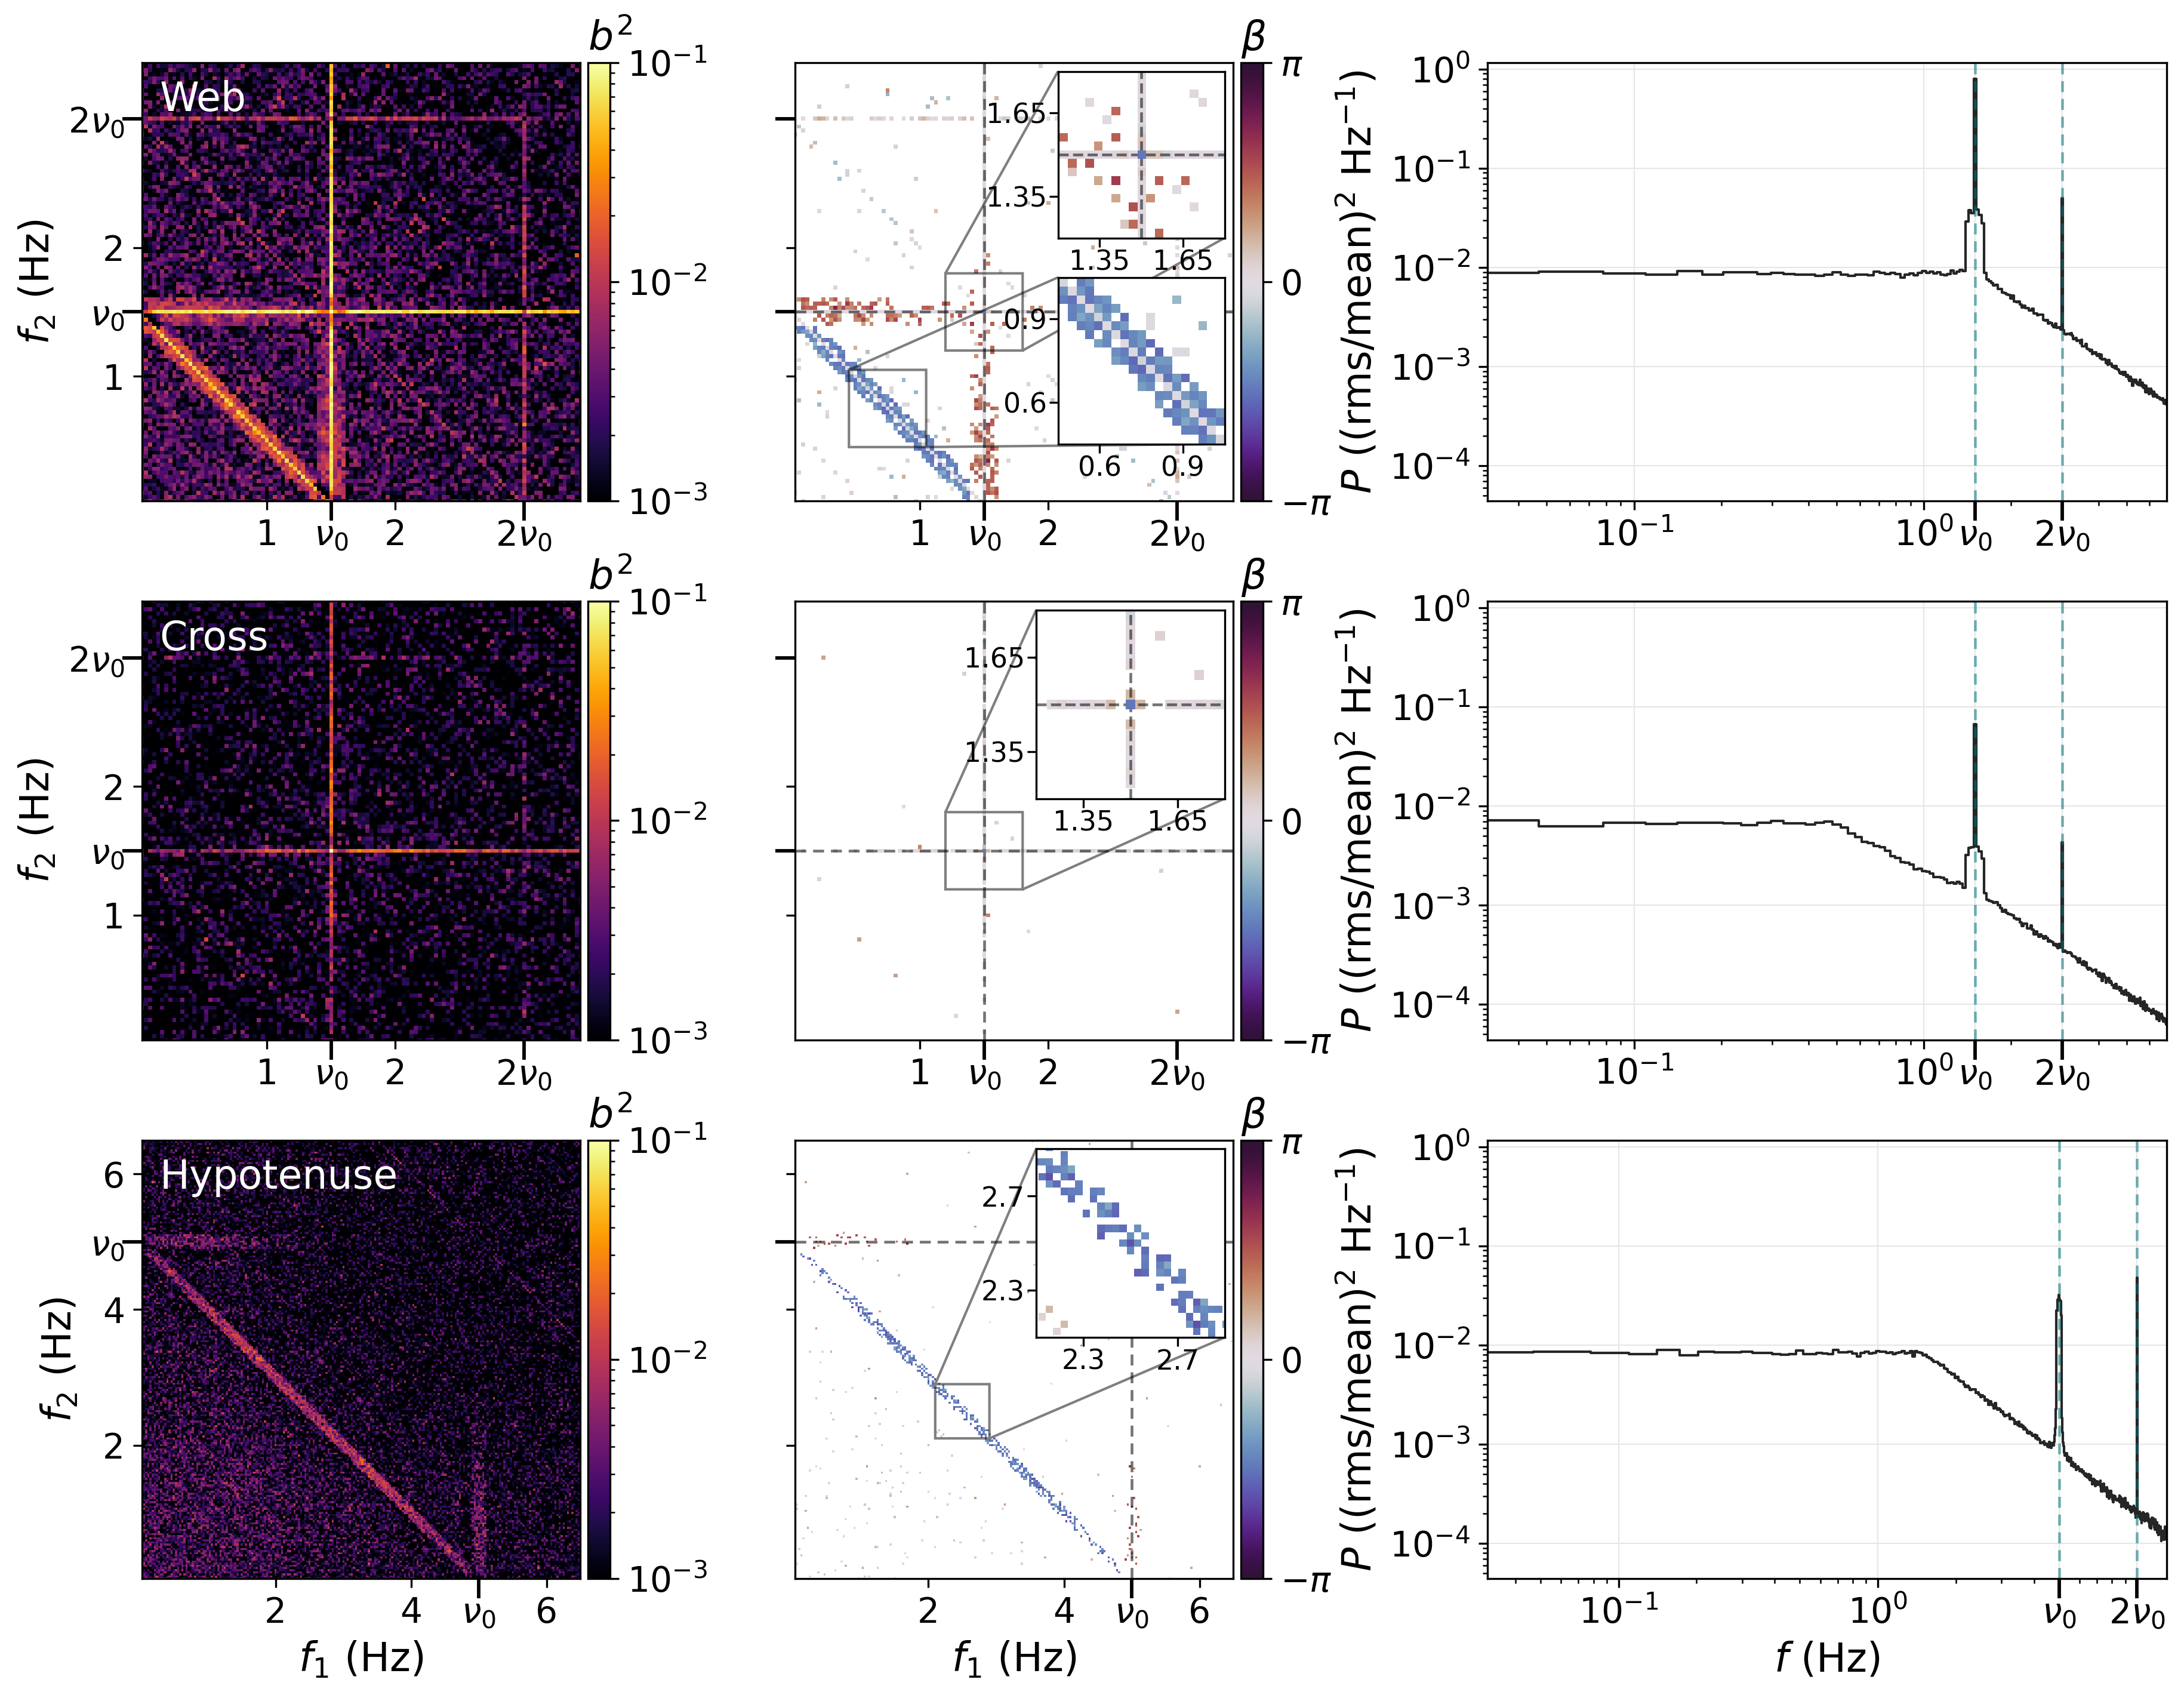

In [6]:
with plt.rc_context(paper_rc):
    fig, axes = plot_patterns(items[:3], row_labels[:3], height=9.3)
    nu0 = [pdata[4] for _, pdata in items]
    # web: two insets down the right side, (nu0, nu0) above and the ridge centre below
    zoom_inset(axes[0, 1], nu0[0], 0.3, origin=(0.6, 0.6), size=0.38)
    zoom_inset(axes[0, 1], nu0[0] / 2, 0.3, origin=(0.6, 0.13), size=0.38)
    # cross at the arm crossing (nu0, nu0); hypotenuse at the ridge centre (nu0/2, nu0/2)
    zoom_inset(axes[1, 1], nu0[1], 0.3)
    zoom_inset(axes[2, 1], nu0[2] / 2, 0.4)

    common_psd_ylim(axes)

    plt.savefig(f'{OUTROOT}/patterns_9panel.pdf', bbox_inches='tight', pad_inches=0.03)
    plt.show(fig)

## Figure: the same plus the point state

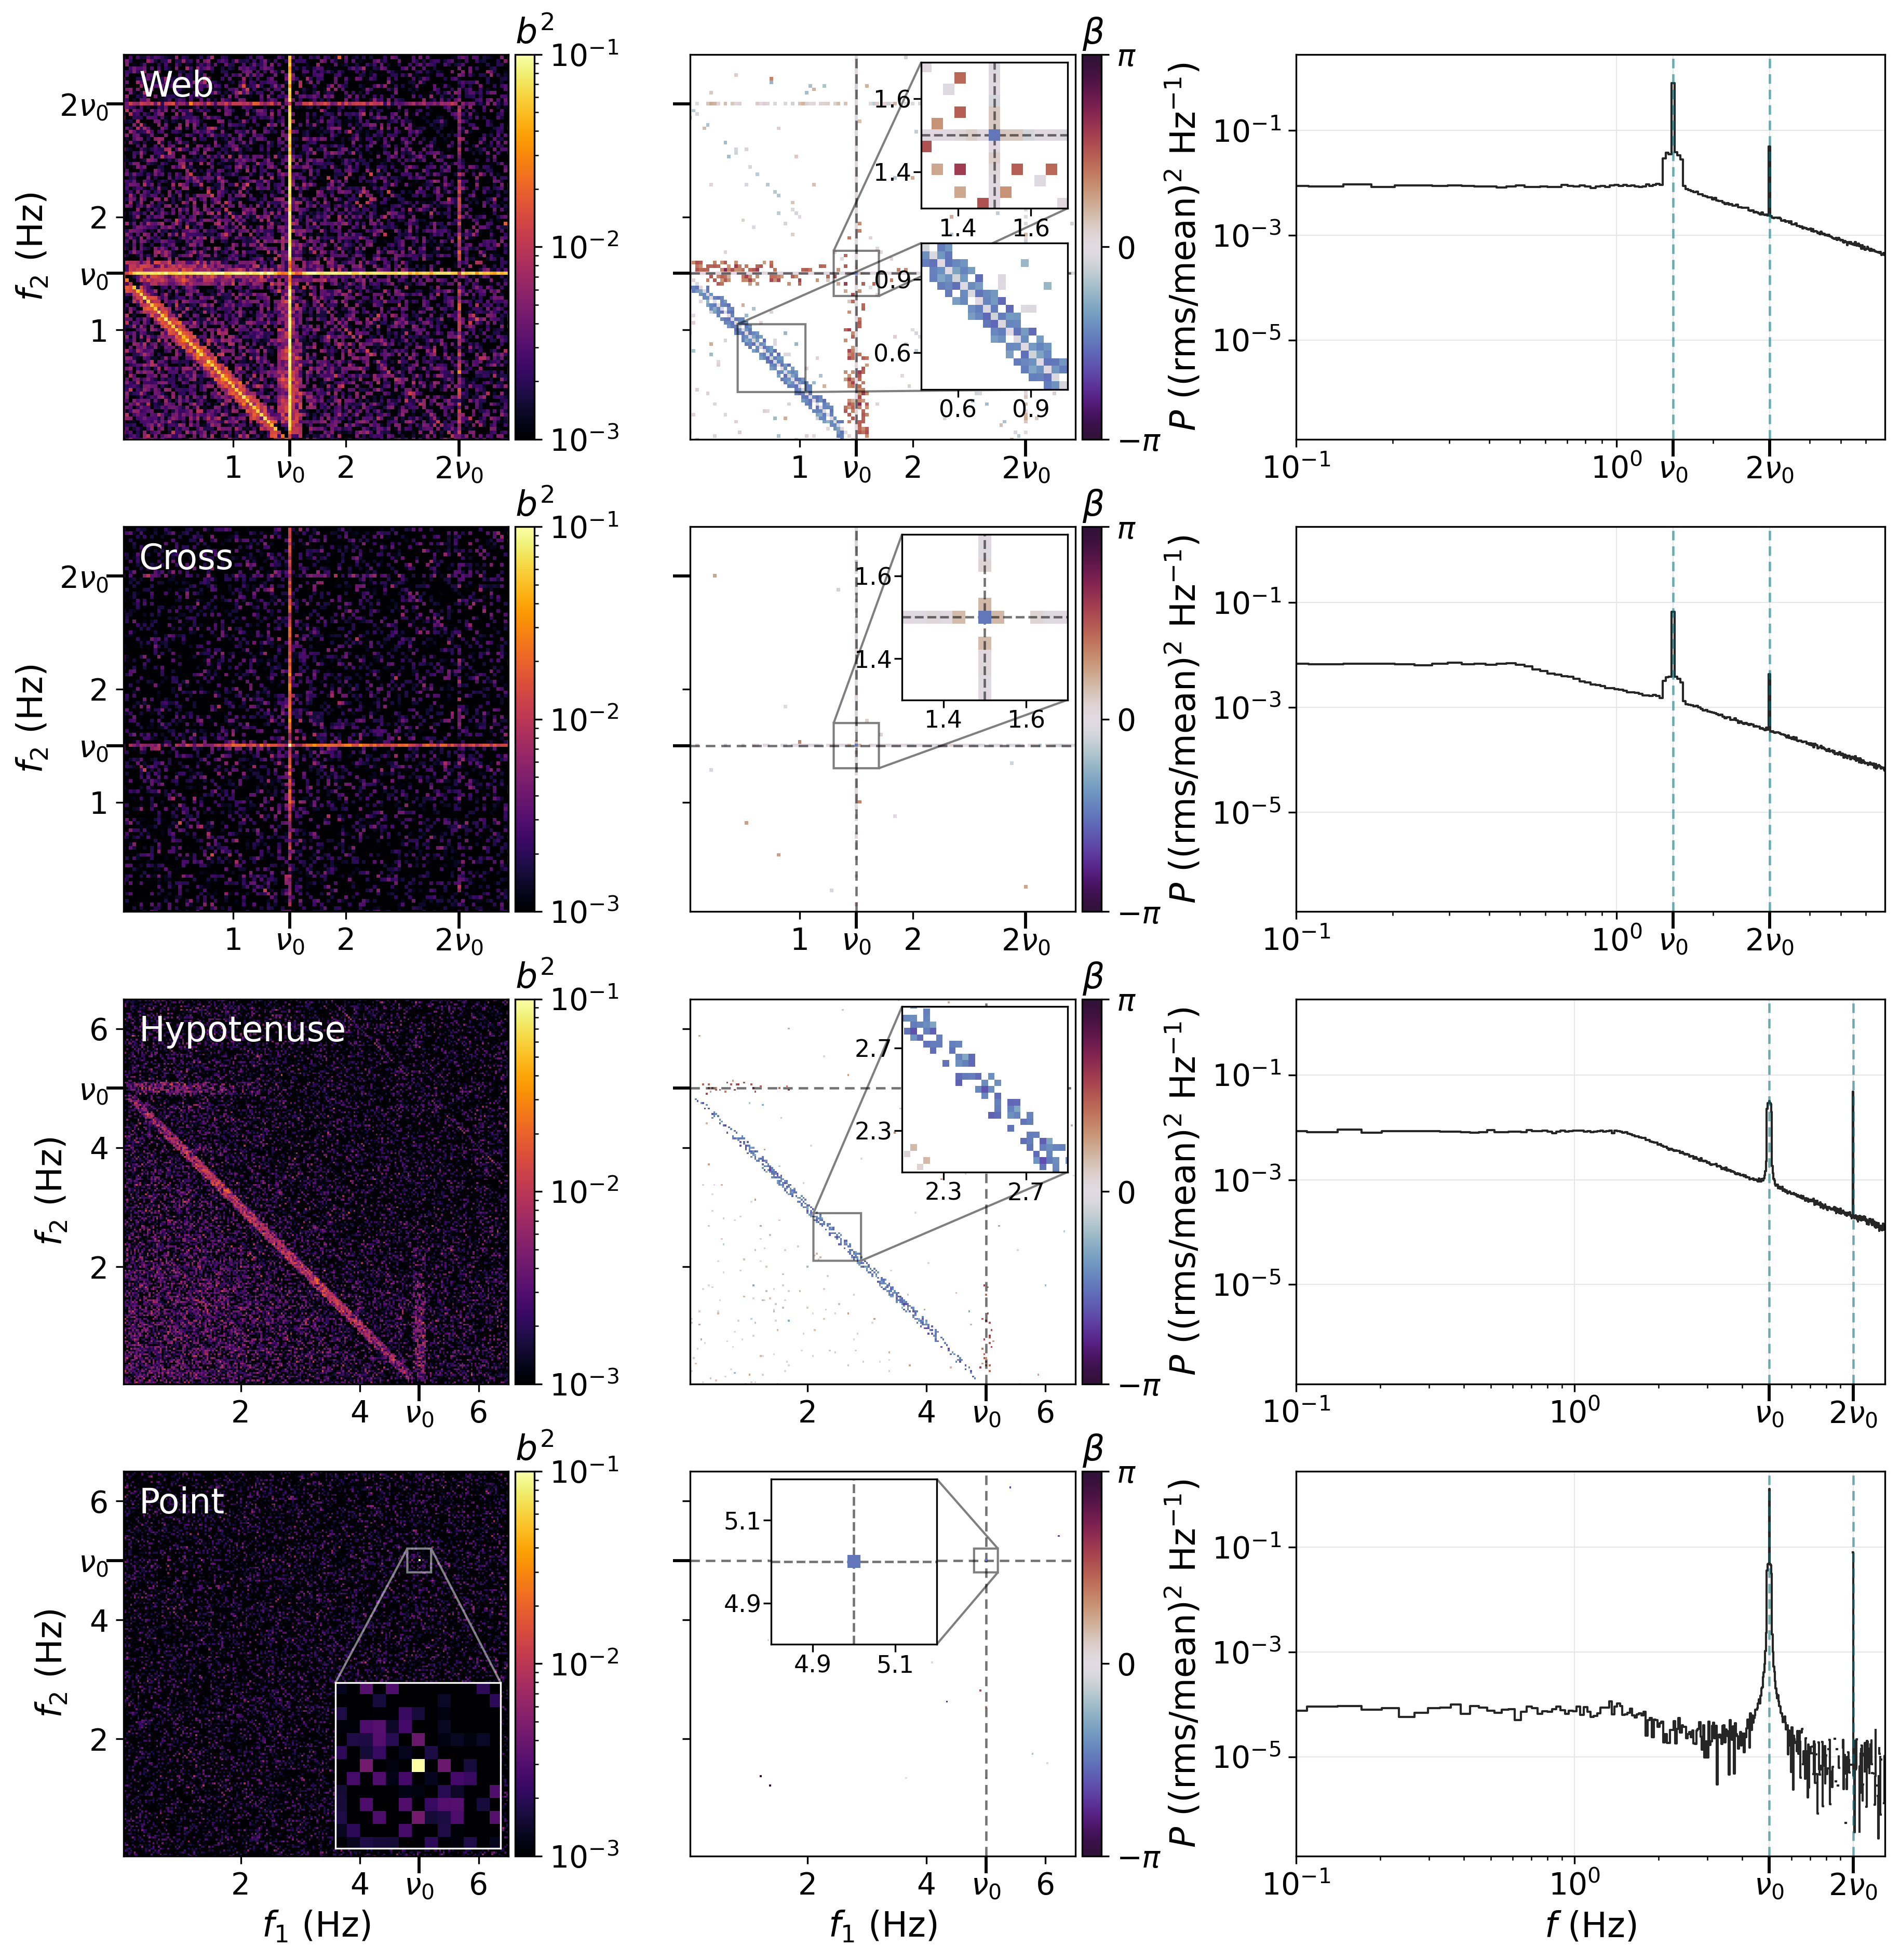

In [7]:
with plt.rc_context(paper_rc):
    fig, axes = plot_patterns(items, row_labels, height=12.4)
    nu0 = [pdata[4] for _, pdata in items]
    # web: two insets down the right side, (nu0, nu0) above and the ridge centre below
    zoom_inset(axes[0, 1], nu0[0], 0.2, origin=(0.6, 0.6), size=0.38)
    zoom_inset(axes[0, 1], nu0[0] / 2, 0.3, origin=(0.6, 0.13), size=0.38)
    # cross at (nu0, nu0); hypotenuse at the ridge centre (nu0/2, nu0/2)
    zoom_inset(axes[1, 1], nu0[1], 0.2)
    zoom_inset(axes[2, 1], nu0[2] / 2, 0.4)
    # point: (nu0, nu0) sits in the upper right, so these insets move clear of it. The b2
    # inset (lower right, white frame on the dark map) shows the same window, unlabelled.
    zoom_inset(axes[3, 0], nu0[3], 0.2, origin=(0.55, 0.02), ticks=False, edgecolor='w')
    zoom_inset(axes[3, 1], nu0[3], 0.2, origin=(0.21, 0.55))  # room for y labels

    # truncate the left edge of the power spectra
    for ax in axes[:, -1]:
        ax.set_xlim((.1, None))

    common_psd_ylim(axes)

    plt.savefig(f'{OUTROOT}/patterns_12panel.pdf', bbox_inches='tight', pad_inches=0.03)
    plt.show(fig)

## (η, 𝒬) planes

Each plane is a grid of 31 values of a₁ × 36 dilution rms (1116 runs, K = 3000).
Shading shows the pattern predicted by b²_hyp / b²_cross ≈ W |1 + 𝒬 e^{−iα}|² / (1 + η),
with α the phase of κ₂ in that grid's runs (α = π/2 on the web-matched base, so 1 + 𝒬²);
markers show the pattern measured in each run.

The grids are loaded from the saved JSON files next to this notebook. If a file is
missing, the grid is re-simulated, about 10 min on 11 workers. `run_grid` restores
`sm.K` afterwards, so the setting from the Setup cell is kept.

In [8]:
def plot_eta_Q(runs, path, argk, xlim=None, ylim=None):
    """Draw one (eta, Q) plane from a list of grid runs and save it to `path`."""
    fig, ax = plt.subplots(figsize=(6.8, 5.3), layout='constrained')  # keeps outside legends in frame
    dq.plot_plane(ax, runs, label_a1=(), region_labels=False, size_by_b2=True,
                  size_scale=dq_scale, argk=argk)
    # pattern legend above the plot
    fig.legend(handles=dq.legend_handles(ms=6), fontsize=8, frameon=False, ncol=4,
               loc='outside upper center', handletextpad=0.3)
    # marker-size legend to the right
    ax.legend(handles=dq.size_handles(size_scale=dq_scale), title=r'$b^2$', fontsize=8,
              title_fontsize=8, frameon=False, loc='center left', bbox_to_anchor=(1.0, 0.5),
              labelspacing=1.2, borderpad=0.2)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

    ax.set_xlabel(r'Low $f$ dilution fraction: $\overline{\eta_-}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
    ax.set_ylabel(r'Coupling ratio: $\overline{\mathcal{Q}}(0.15 \nu_0 \leq f_1 \leq 0.45 \nu_0)$')
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)

    plt.savefig(path)
    plt.show(fig)
    pprint({k: sum(r['pattern'] == k for r in runs) for k in dq.PAT})  # runs per pattern

### Figure: (η, 𝒬) plane

Base parameters: `dq.BASE` in `sim_dQ_grid.py`. Same grid as
`python sim_dQ_grid.py --extra-dense`.

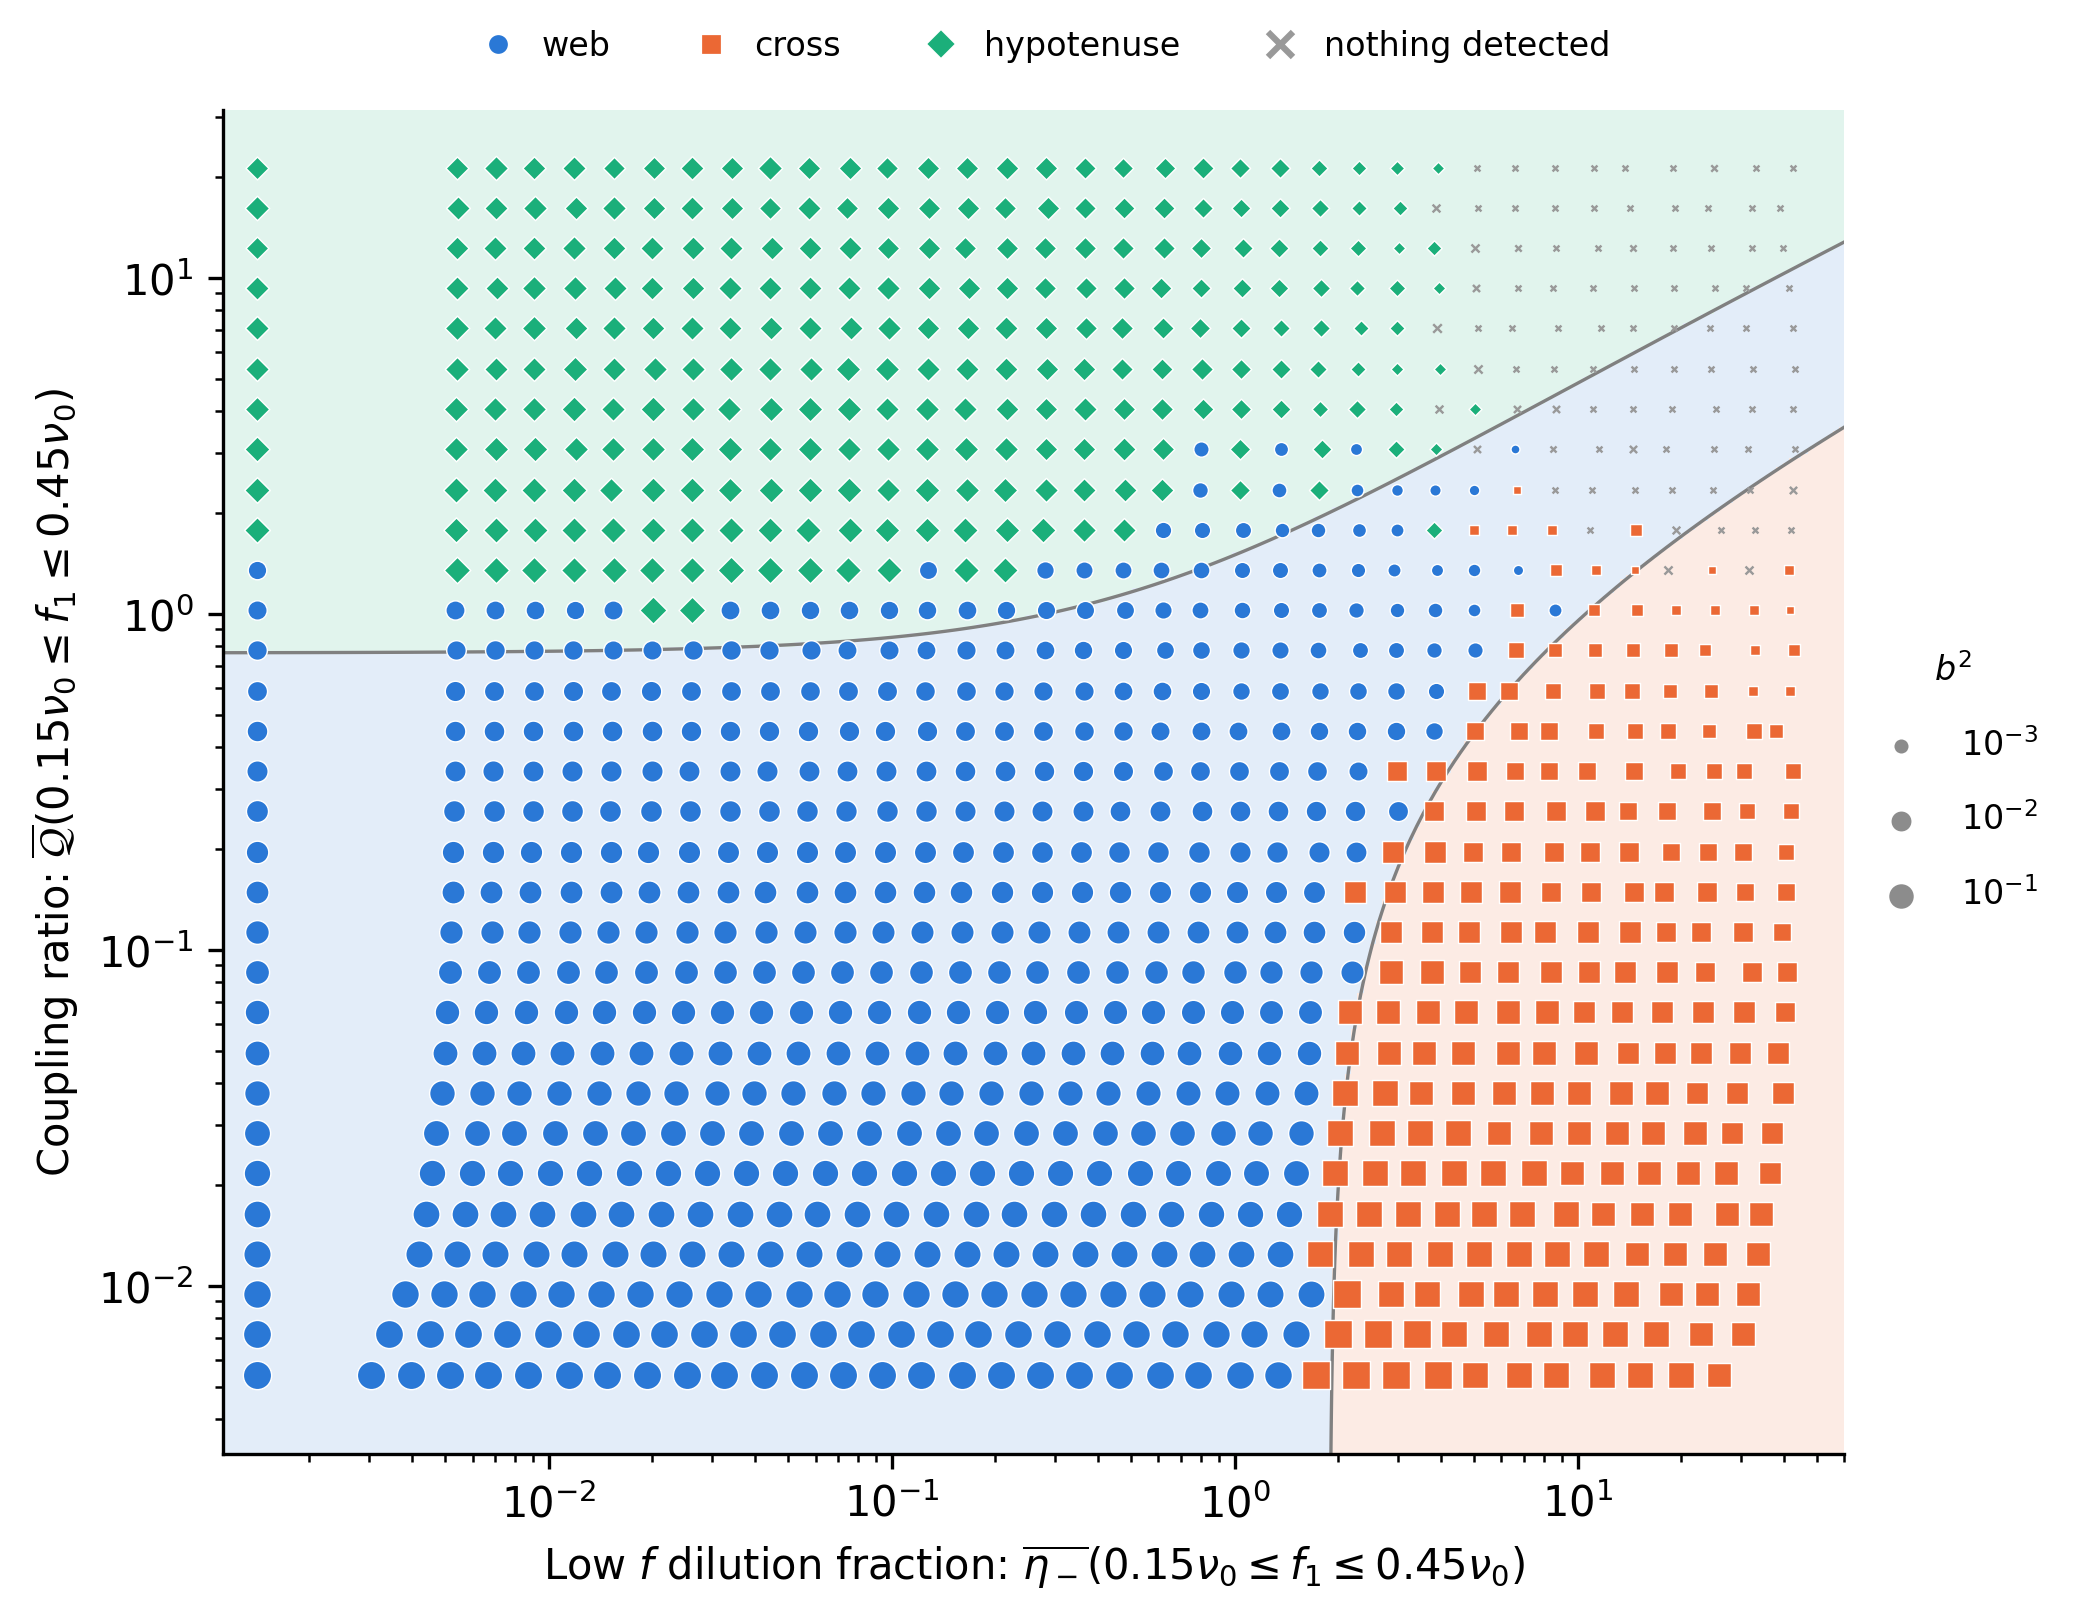

{'cross': 226, 'hyp': 269, 'none': 87, 'web': 534}


In [9]:
dq_path = os.path.join(dq.OUT, 'sim_dQ_grid_extra_dense.json')
if os.path.exists(dq_path):
    with open(dq_path) as fh:
        dq_runs = json.load(fh)['runs']
else:
    dq_runs = dq.run_grid('extra_dense', path=dq_path)

plot_eta_Q(dq_runs, f'{OUTROOT}/eta_Q_grid.pdf', dq.BASE.argk, xlim=(None, 60))

### Figure: (η, 𝒬) plane on the web-matched base

Base parameters: `DQ_WEB_BASE` from the Model parameters cell. The dilution rms is
scaled by 1/D, so D × nd_rms matches the first plane. The saved grid is used only
if it was run on the same base.

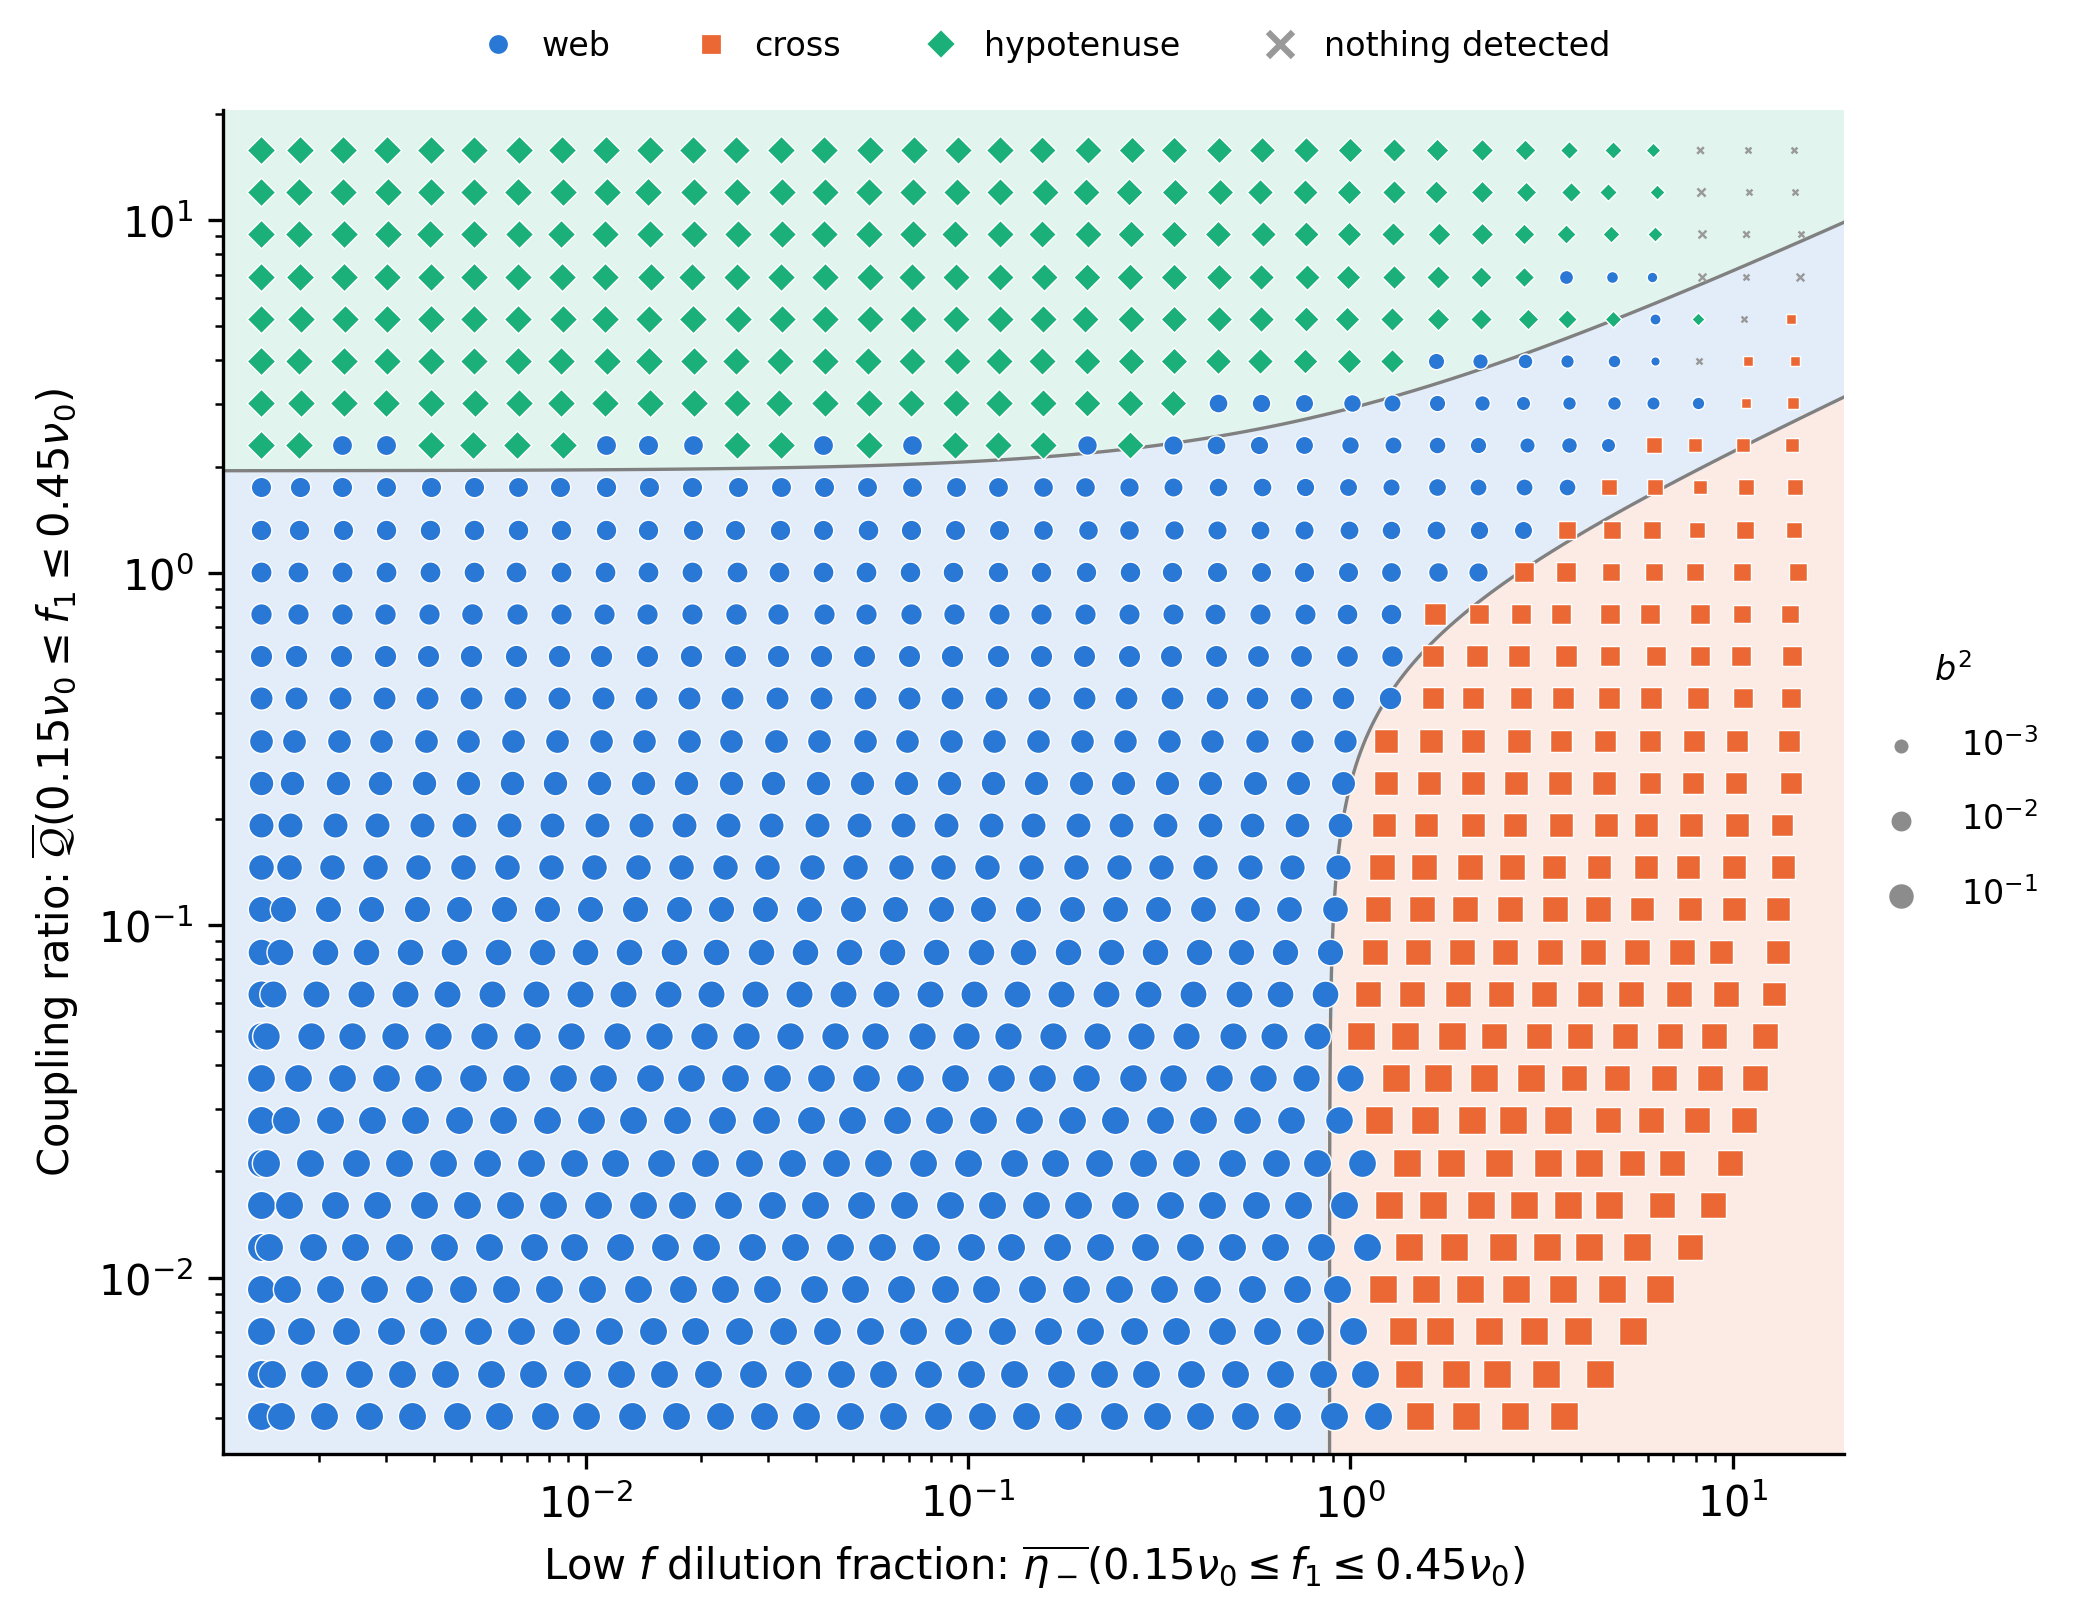

{'cross': 197, 'hyp': 224, 'none': 14, 'web': 681}


In [10]:
dq_web_path = os.path.join(dq.OUT, 'sim_dQ_grid_extra_dense_web.json')
dq_web = json.load(open(dq_web_path)) if os.path.exists(dq_web_path) else None
if dq_web is not None and dq_web['base'] == repr(DQ_WEB_BASE):
    dq_web_runs = dq_web['runs']
else:
    dq_web_runs = dq.run_grid('extra_dense_web', path=dq_web_path, workers=11, base=DQ_WEB_BASE)

plot_eta_Q(dq_web_runs, f'{OUTROOT}/eta_Q_grid_web.pdf', DQ_WEB_BASE.argk,
           xlim=(None, 1.3 * max(r['d'] for r in dq_web_runs)),  # just past the last column
           ylim=(None, 1.3 * max(r['Q'] for r in dq_web_runs)))